# TP2 — Etapa 2: entrenamiento, evaluación y comparación de modelos

Esta notebook evalúa la búsqueda por similitud (Etapa 1) y entrena/compara los dos modelos
obligatorios (Modelo A: ResNet con fine-tuning; Modelo B: CNN propia).

**Requisitos:** haber ejecutado `1-pre-processing.py`. De ahí salen `splits/*.csv` y las copias
aumentadas en `data/dataset/augmented/`. Se corre **desde la raíz del repositorio** con el
ambiente local (`.venv`); no hay pasos de Colab.

**Partición por grupos.** Las celdas leen los manifiestos vigentes. Las salidas
guardadas de esta notebook y los checkpoints de clasificación existentes
corresponden a la partición anterior. Para medir los clasificadores con el
nuevo reparto, entrená nuevos checkpoints en otro directorio. El registro de
los archivos históricos está en [splits/README.md](splits/README.md).

## Equipo
- Alejandro Armas
- Gabriel Soda

## 1. Configuración del entorno

Paths y configuración salen de `lib.config` (`.env`). La galería de la Etapa 1 es
`splits/train_augmented.csv` (originales + copias que balancean las clases).

In [ ]:
import json
import os
import sys
import time
from pathlib import Path

# Antes de importar torch/lib: caché de pesos y store JSON (la evaluación no usa Postgres).
os.environ.setdefault("USE_PGVECTOR", "false")
os.environ.setdefault("TORCH_HOME", str(Path.cwd() / "models" / "torch"))

import altair as alt
import cv2
import numpy as np
import polars as pl
import torch
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / "splits").is_dir():
    raise SystemExit("Ejecutá la notebook desde la raíz del repo: falta splits/.")
sys.path.insert(0, str(ROOT / "src"))

from lib.bootstrap import build_classifier, build_similarity
from lib.config import settings
from lib.evaluation.metrics import ndcg_at_k
from lib.schemas import Neighbor

alt.data_transformers.disable_max_rows()

SEED = 42
# 0 = usar todos los datos. Con un valor chico (ej. 5) se hace una prueba rápida de punta a punta.
LIMIT_PER_CLASS = int(os.getenv("LIMIT_PER_CLASS", 0))

COLORS = {
    "primary": "#4c78a8",
    "secondary": "#f58518",
    "negative": "#e45756",
    "positive": "#54a24b",
    "neutral": "#72b7b2",
    "gray": "#b3b3b3",
}
CATEGORICAL_COLORS = [
    COLORS["primary"], COLORS["secondary"], COLORS["negative"], COLORS["positive"],
    COLORS["neutral"], "#f2cf4a", "#9d7660", "#b279a2", "#ff9da6", "#4c78a8",
]

NOMBRES_ES = {
    "split": "partición",
    "breed": "raza",
    "path": "ruta",
    "filename": "archivo",
    "images": "imágenes",
    "metric": "métrica",
    "model": "modelo",
    "strategy": "estrategia",
    "epoch": "época",
    "duration_seconds": "duración (s)",
    "serie": "serie",
    "loss": "loss",
    "value": "valor",
    "accuracy": "exactitud",
    "precision": "precisión",
    "recall": "recall",
    "specificity": "especificidad",
    "f1": "F1",
    "umbral": "umbral",
    "cobertura": "cobertura",
    "rank": "puesto",
    "real": "real",
    "predicha": "predicha",
    "n": "imágenes",
    "proporción": "proporción",
    "support": "imágenes",
    "consulta": "consulta",
    "raza_real": "raza real",
    "raza_vecino": "raza del vecino",
    "score": "score",
    "train_loss": "loss train",
    "valid_loss": "loss valid",
    "train_accuracy": "exactitud train",
    "valid_accuracy": "exactitud valid",
    "valid_f1": "F1 valid",
    "ndcg@10": "NDCG@10",
    "precision@10": "precision@10",
    "precision@1": "precision@1",
}


def inline(df: pl.DataFrame) -> alt.InlineData:
    """Convierte un DataFrame de Polars a InlineData para Altair."""
    return alt.InlineData(values=df.to_dicts())


def mostrar(df: pl.DataFrame) -> None:
    """Muestra un DataFrame con los nombres de columnas en español."""
    display(df.rename({k: v for k, v in NOMBRES_ES.items() if k in df.columns}))


print("dataset:", settings.dataset_path)
print("splits: ", settings.splits_path)
print("modelos:", settings.model_path)
print("salidas:", settings.output_path)
print("dispositivo:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")

## 2. Dataset y splits

Decisiones:

- **Reparto por grupos de fotos**, con objetivo de 70/15/15 de originales por raza.
  Lo genera `1-pre-processing.py` después de aplicar el filtro de calidad.
- **Galería (Etapa 1) = `train_augmented`**: más vecinos por raza y ninguna consulta indexada
  (test y el conjunto independiente nunca se aumentan).
- **Entrenamiento (Etapa 2) = el mismo `train_augmented`** (las clases quedan parejas);
  `valid` se usa para early stopping y calibración del umbral; `test` se toca una sola vez, al final.

In [ ]:
def load_split(name: str) -> pl.DataFrame:
    path = settings.splits_path / f"{name}.csv"
    if not path.exists():
        raise FileNotFoundError(f"Falta {path}. Ejecutá 1-pre-processing.py.")
    return pl.read_csv(path)


train_df = load_split("train_augmented")
valid_df = load_split("valid")
test_df = load_split("test")

if LIMIT_PER_CLASS:
    print(f"LIMIT_PER_CLASS={LIMIT_PER_CLASS}: submuestra para prueba rápida")
    train_df = train_df.group_by("breed", maintain_order=True).head(LIMIT_PER_CLASS)
    valid_df = valid_df.group_by("breed", maintain_order=True).head(LIMIT_PER_CLASS)
    test_df = test_df.group_by("breed", maintain_order=True).head(LIMIT_PER_CLASS)

splits_long = pl.concat(
    [
        train_df.select("breed").with_columns(pl.lit("train (galería)").alias("split")),
        valid_df.select("breed").with_columns(pl.lit("valid").alias("split")),
        test_df.select("breed").with_columns(pl.lit("test").alias("split")),
    ]
)
resumen_splits = (
    splits_long.group_by(["split", "breed"])
    .len()
    .group_by("split")
    .agg(
        pl.len().alias("razas"),
        pl.col("len").sum().alias("imágenes"),
        pl.col("len").min().alias("mín por raza"),
        pl.col("len").max().alias("máx por raza"),
    )
    .sort("split")
)
mostrar(resumen_splits)

## 3. Etapa 1 — Evaluación de la búsqueda por similitud (baseline)

Sección 4.3. Se usa el ResNet18 preentrenado de `SimilarityService`, con
embeddings L2-normalizados. La galería es `splits/train_augmented.csv`, el manifiesto que
indexa la app. `valid` calibra el rechazo. La evaluación final usa `test` y las fotos de
un solo perro de `splits/independent_manifest.csv` con su raza etiquetada.
Se cruzan las rutas locales y los identificadores de origen de cada consulta con las
rutas indexadas y las rutas originales de las copias aumentadas. Se verifica también
la coincidencia exacta de archivos por SHA-256.

Para repetir la corrida completa, se debe abrir la notebook desde la raíz del repo con el kernel de
la `.venv` y `LIMIT_PER_CLASS=0`. Luego, ejecutar las celdas de configuración y splits de las
secciones 1 y 2, y todas las celdas de esta sección hasta los ejemplos.

In [4]:
from hashlib import sha256
from io import BytesIO
from textwrap import fill

from IPython.display import Image, Markdown
from matplotlib.figure import Figure

BASELINE_METRICS = ("cosine", "l2")
BASELINE_K = 10
gallery_df = train_df.sort("breed", maintain_order=True)
independent_df = load_split("independent_manifest").filter(pl.col("scene_type") == "un_perro")


def ruta_clave(value: str) -> str:
    if "://" in value:
        return value
    return os.path.normcase(str((settings.dataset_path / value).resolve()))


indexed_paths = set(map(ruta_clave, gallery_df["path"]))
gallery_origins = {
    ruta_clave(value) for value in gallery_df["origin"] if value and value != "original"
}
if len(indexed_paths) != gallery_df.height:
    raise ValueError("Hay rutas de galería repetidas en train_augmented.csv.")

gallery_identifiers = indexed_paths | gallery_origins
gallery_hashes = {sha256(Path(path).read_bytes()).digest() for path in gallery_identifiers}
split_checks = []
for split, queries in (("valid", valid_df), ("test", test_df), ("independiente", independent_df)):
    query_paths = set(map(ruta_clave, queries["path"]))
    query_origins = {
        ruta_clave(value)
        for column in ("origin", "source")
        if column in queries.columns
        for value in queries[column].drop_nulls()
        if value and value != "original"
    }
    shared_paths = query_paths & gallery_identifiers
    shared_origins = query_origins & gallery_identifiers
    identical_files = sum(
        sha256(Path(path).read_bytes()).digest() in gallery_hashes for path in query_paths
    )
    if len(query_paths) != queries.height or shared_paths or shared_origins or identical_files:
        raise ValueError(
            f"{split}: hay consultas repetidas o presentes en la galería. "
            f"Rutas compartidas: {sorted(shared_paths | shared_origins)}. "
            f"Archivos idénticos: {identical_files}."
        )
    split_checks.append(
        {
            "Partición": split,
            "Imágenes": queries.height,
            "Razas": queries["breed"].n_unique(),
            "Rutas en galería": len(shared_paths),
            "Orígenes en galería": len(shared_origins),
            "Archivos idénticos": identical_files,
        }
    )

print(f"LIMIT_PER_CLASS={LIMIT_PER_CLASS} · ResNet18 · {'CUDA' if torch.cuda.is_available() else 'CPU'}")
display(pl.DataFrame([{
    "Galería": "splits/train_augmented.csv",
    "Imágenes": gallery_df.height,
    "Razas": gallery_df["breed"].n_unique(),
}]))
display(pl.DataFrame(split_checks))

LIMIT_PER_CLASS=0 · ResNet18 · CPU


Galería,Imágenes,Razas
str,i64,i64
"""splits/train_augmented.csv""",10570,70


Partición,Imágenes,Razas,Rutas en galería,Orígenes en galería,Archivos idénticos
str,i64,i64,i64,i64,i64
"""valid""",1379,70,0,0,0
"""test""",1379,70,0,0,0
"""independiente""",25,12,0,0,0


In [5]:
baseline = build_similarity(settings.model_copy(update={"embedding_model": "baseline"}), store=None)
gallery_paths = gallery_df["path"].to_list()
gallery_breeds = gallery_df["breed"].to_list()
gallery_counts = dict(gallery_df.group_by("breed").len().iter_rows())


def baseline_image(relative_path: str) -> np.ndarray:
    path = (settings.dataset_path / relative_path).resolve()
    image = cv2.imread(str(path))
    if image is None:
        raise FileNotFoundError(f"No se pudo leer {path}")
    return image


def embed_baseline(rows: pl.DataFrame, label: str, batch_size: int = 32) -> np.ndarray:
    paths = rows["path"].to_list()
    embeddings = []
    for start in range(0, len(paths), batch_size):
        images = [baseline_image(path) for path in paths[start : start + batch_size]]
        embeddings.extend(baseline.extract_embeddings(images))
    matrix = np.asarray(embeddings, dtype=np.float32)
    print(f"{label}: {len(matrix):,} embeddings de {matrix.shape[1]} dimensiones.", flush=True)
    return matrix


gallery_emb = embed_baseline(gallery_df, "Galería")
gallery_matrix = gallery_emb.astype(np.float64)
gallery_norm2 = np.einsum("ij,ij->i", gallery_matrix, gallery_matrix)


def retrieve_baseline(query_emb: np.ndarray) -> dict[str, list[list[Neighbor]]]:
    """Busca en la galería completa por lotes y puntúa el top con el servicio."""
    rankings = {metric: [] for metric in BASELINE_METRICS}
    for start in range(0, len(query_emb), 128):
        query_batch = query_emb[start : start + 128]
        query_matrix = query_batch.astype(np.float64)
        query_norm2 = np.einsum("ij,ij->i", query_matrix, query_matrix)[:, None]
        dot = query_matrix @ gallery_matrix.T
        cosine = dot / np.sqrt(query_norm2 * gallery_norm2)
        distance2 = query_norm2 + gallery_norm2 - 2 * dot

        for metric, order_by in (("cosine", -cosine), ("l2", distance2)):
            baseline.similarity_metric = metric
            columns = np.argsort(order_by, axis=1, kind="stable")[:, :BASELINE_K]
            for embedding, indices in zip(query_batch, columns, strict=True):
                neighbors = [
                    Neighbor(
                        path=gallery_paths[column],
                        breed=gallery_breeds[column],
                        score=baseline.similarity(embedding, gallery_emb[column]),
                    )
                    for column in indices
                ]
                neighbors.sort(key=lambda neighbor: neighbor.score, reverse=True)
                rankings[metric].append(neighbors)
    return rankings


def predict_baseline(rankings: list[list[Neighbor]], k: int, threshold: float) -> np.ndarray:
    baseline.similarity_threshold = threshold
    return np.array([
        baseline.predict_breed_from_neighbors(neighbors[:k])[0] for neighbors in rankings
    ])


def rank_metrics(rankings: list[list[Neighbor]], breeds: np.ndarray, k: int) -> np.ndarray:
    values = []
    for neighbors, breed in zip(rankings, breeds, strict=True):
        relevance = [float(neighbor.breed == breed) for neighbor in neighbors[:k]]
        ndcg = ndcg_at_k(relevance, k=k, n_relevant=gallery_counts.get(breed, 0))
        values.append((ndcg, sum(relevance) / k))
    return np.asarray(values)

Galería: 10,570 embeddings de 512 dimensiones.


### Calibración en validación

Para cada métrica y K se obtiene el voto ponderado de `predict_breed_from_neighbors`.
Se barren umbrales de 0 a 1 en pasos de 0.001 sobre el mejor score de cada consulta,
con la regla de la app: se devuelve `unknown` si el mejor score es menor que el umbral.
Se maximiza el **F1 de aciertos aceptados**, la media armónica entre la fracción de
aciertos entre las aceptadas y la fracción de aciertos sobre todas las consultas. Si hay
empate se prioriza el umbral más bajo. Valid contiene razas conocidas, así que el rechazo
se calibra como abstención ante errores de voto.

En ambas escalas, mayor score significa más similitud. Cosine normaliza el producto
escalar y L2 usa `1 / (1 + distancia euclídea)`. Para embeddings unitarios los rankings
pueden coincidir, y cada escala da pesos distintos al voto. La accuracy cuenta
`unknown` como error. NDCG y precision miden los vecinos recuperados en todas las consultas.

In [6]:
valid_rankings = retrieve_baseline(embed_baseline(valid_df, "Validación"))
valid_breeds = valid_df["breed"].to_numpy()
threshold_grid = np.arange(1001) / 1000
calibration_rows = []
baseline_thresholds = {}

for metric, rankings in valid_rankings.items():
    best_scores = np.array([neighbors[0].score for neighbors in rankings])
    accepted = best_scores[None, :] >= threshold_grid[:, None]
    n_accepted = accepted.sum(axis=1)
    for k in (5, BASELINE_K):
        unfiltered = predict_baseline(rankings, k, -np.inf)
        hits = unfiltered == valid_breeds
        n_hits = (accepted & hits).sum(axis=1)
        f1 = 2 * n_hits / (len(valid_breeds) + n_accepted)
        chosen = int(f1.argmax())
        threshold = float(threshold_grid[chosen])
        predicted = predict_baseline(rankings, k, threshold)
        if k == BASELINE_K:
            baseline_thresholds[metric] = threshold

        ndcg, precision = rank_metrics(rankings, valid_breeds, k).mean(axis=0)
        covered = predicted != "unknown"
        calibration_rows.append({
            "Métrica": metric,
            "K": k,
            "Umbral": threshold,
            "NDCG@K": ndcg,
            "precision@K": precision,
            "Accuracy sin rechazo (%)": 100 * hits.mean(),
            "Accuracy (%)": 100 * (predicted == valid_breeds).mean(),
            "Aciertos entre aceptadas (%)": 100 * (predicted[covered] == valid_breeds[covered]).mean(),
            "Unknown (%)": 100 * (~covered).mean(),
            "F1": f1[chosen],
        })

with pl.Config(tbl_cols=-1, float_precision=4):
    display(pl.DataFrame(calibration_rows))

print(f"Umbrales fijados para K={BASELINE_K}: " + ", ".join(
    f"{metric}={threshold:.3f}" for metric, threshold in baseline_thresholds.items()
))

Validación: 1,379 embeddings de 512 dimensiones.


Métrica,K,Umbral,NDCG@K,precision@K,Accuracy sin rechazo (%),Accuracy (%),Aciertos entre aceptadas (%),Unknown (%),F1
str,i64,f64,f64,f64,f64,f64,f64,f64,f64
"""cosine""",5,0.7500,0.8519,0.8468,88.9050,88.9050,88.9695,0.0725,0.8894
"""cosine""",10,0.0000,0.8367,0.8273,89.4851,89.4851,89.4851,0.0000,0.8949
"""l2""",5,0.5860,0.8519,0.8468,88.9050,88.9050,88.9695,0.0725,0.8894
"""l2""",10,0.0000,0.8367,0.8273,89.5577,89.5577,89.5577,0.0000,0.8956


Umbrales fijados para K=10: cosine=0.000, l2=0.000


### Evaluación final con K=10

Se aplican los umbrales fijados en validación. La relevancia es binaria por raza y
`ndcg_at_k` usa el número de imágenes de la raza en toda la galería para calcular el ideal.
La precision@10 es la fracción de vecinos de la raza real entre los diez recuperados.

In [7]:
baseline_results = {}
baseline_rows = []
for split, queries in (("test", test_df), ("independiente", independent_df)):
    breeds = queries["breed"].to_numpy()
    rankings_by_metric = retrieve_baseline(embed_baseline(queries, split))
    for metric, rankings in rankings_by_metric.items():
        threshold = baseline_thresholds[metric]
        predicted = predict_baseline(rankings, BASELINE_K, threshold)
        ndcg, precision = rank_metrics(rankings, breeds, BASELINE_K).T
        baseline_results[split, metric] = (rankings, predicted, ndcg)
        baseline_rows.append({
            "Conjunto": split,
            "Métrica": metric,
            "Consultas": len(breeds),
            "Umbral": threshold,
            "NDCG@10": ndcg.mean(),
            "precision@10": precision.mean(),
            "Accuracy de raza (%)": 100 * (predicted == breeds).mean(),
            "Unknown (%)": 100 * (predicted == "unknown").mean(),
        })

with pl.Config(tbl_cols=-1, float_precision=4):
    display(pl.DataFrame(baseline_rows))

for split in ("test", "independiente"):
    cosine_ranks, cosine_pred, _ = baseline_results[split, "cosine"]
    l2_ranks, l2_pred, _ = baseline_results[split, "l2"]
    changed_ranks = sum(
        [neighbor.path for neighbor in cosine] != [neighbor.path for neighbor in l2]
        for cosine, l2 in zip(cosine_ranks, l2_ranks, strict=True)
    )
    print(f"{split}: {changed_ranks}/{len(cosine_ranks)} Top-10 con distinto orden, "
          f"{np.count_nonzero(cosine_pred != l2_pred)} predicciones distintas.")

test: 1,379 embeddings de 512 dimensiones.


independiente: 25 embeddings de 512 dimensiones.


Conjunto,Métrica,Consultas,Umbral,NDCG@10,precision@10,Accuracy de raza (%),Unknown (%)
str,str,i64,f64,f64,f64,f64,f64
"""test""","""cosine""",1379,0.0000,0.8357,0.8260,88.5424,0.0000
"""test""","""l2""",1379,0.0000,0.8357,0.8260,88.5424,0.0000
"""independiente""","""cosine""",25,0.0000,0.4915,0.4920,56.0000,0.0000
"""independiente""","""l2""",25,0.0000,0.4915,0.4920,56.0000,0.0000


test: 0/1379 Top-10 con distinto orden, 0 predicciones distintas.
independiente: 0/25 Top-10 con distinto orden, 0 predicciones distintas.


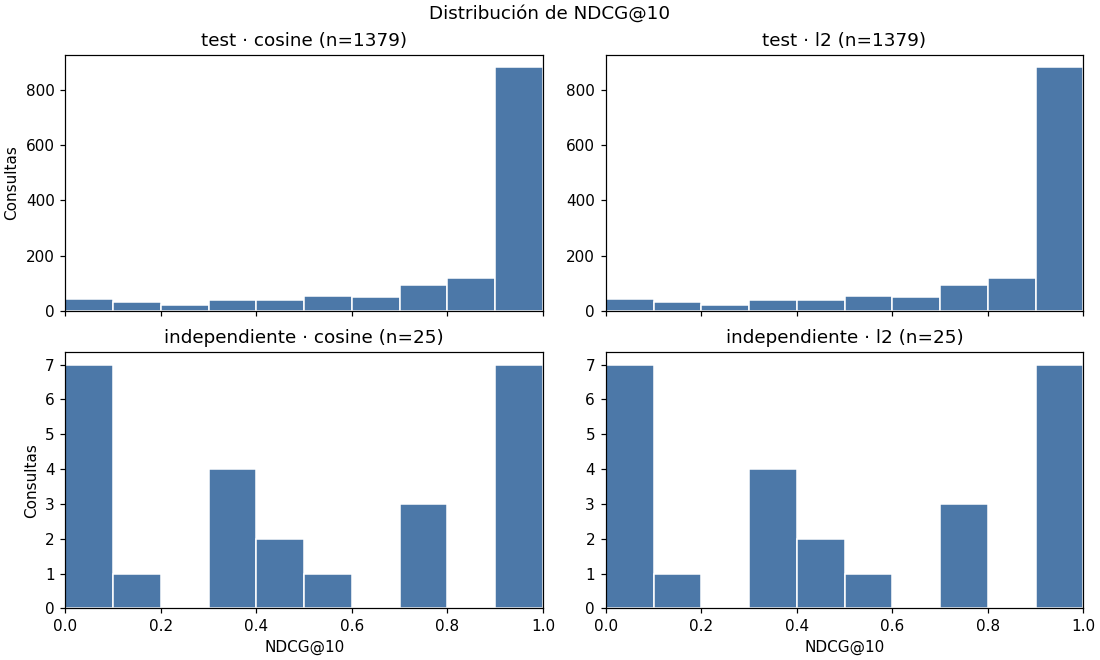

In [8]:
def display_baseline_figure(figure: Figure, title: str) -> None:
    with BytesIO() as buffer:
        figure.savefig(buffer, format="png", dpi=110)
        display(Image(data=buffer.getvalue(), format="png", alt=title))


distribution = Figure(figsize=(10, 6), layout="constrained")
distribution.suptitle("Distribución de NDCG@10")
for axis, ((split, metric), (_, _, ndcg)) in zip(
    distribution.subplots(2, 2, sharex=True).flat, baseline_results.items(), strict=True
):
    axis.hist(ndcg, bins=np.linspace(0, 1, 11), color=COLORS["primary"], edgecolor="white")
    axis.set(title=f"{split} · {metric} (n={len(ndcg)})", xlim=(0, 1))
for axis in distribution.axes[::2]:
    axis.set_ylabel("Consultas")
for axis in distribution.axes[2:]:
    axis.set_xlabel("NDCG@10")
display_baseline_figure(distribution, "Distribución de NDCG@10 por conjunto y métrica")

### Dos consultas y sus vecinos con cosine

Los vecinos se leen de izquierda a derecha en cada fila. Las etiquetas verdes indican
coincidencia con la raza real.

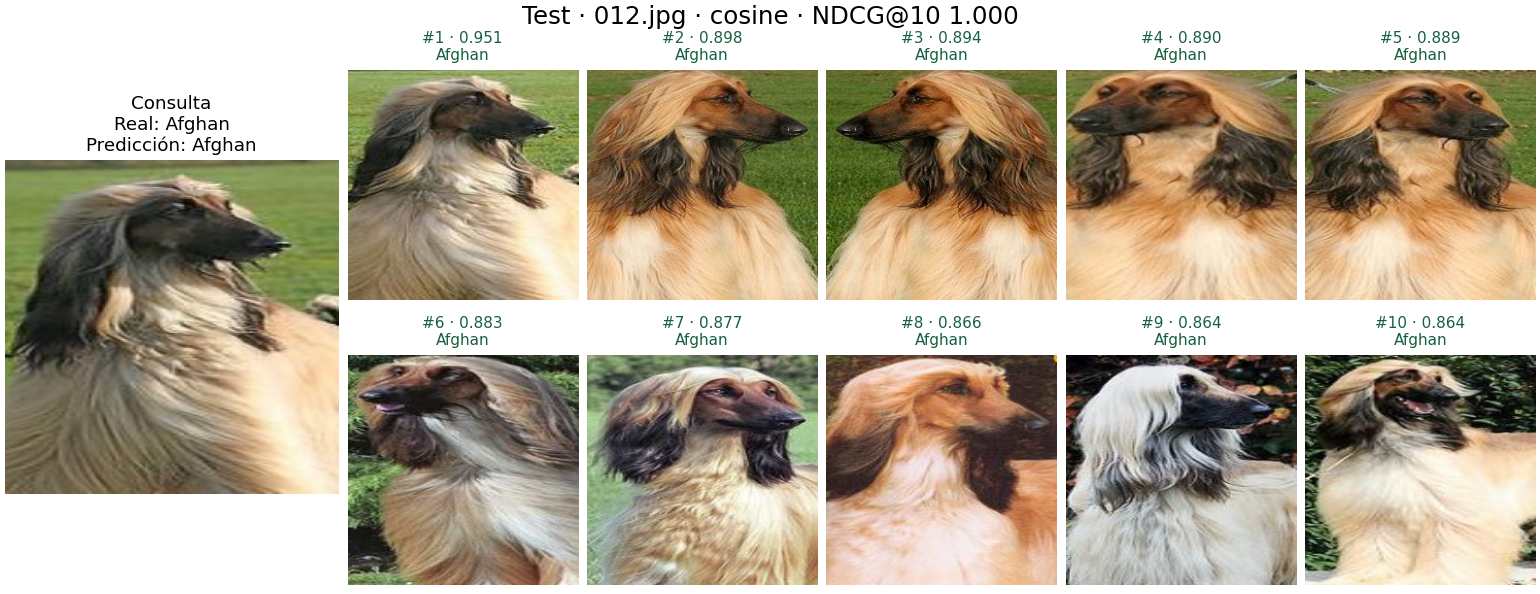

Consulta: train/Afghan/012.jpg


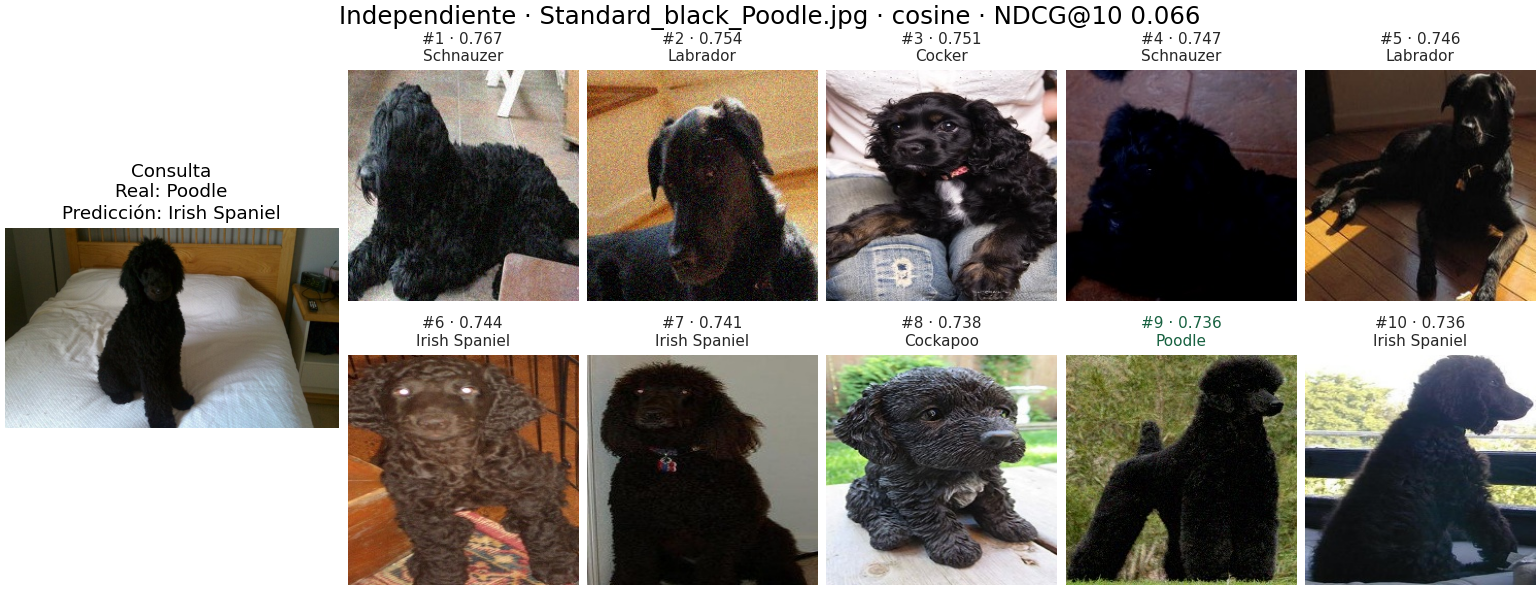

Consulta: independent/Poodle/Standard_black_Poodle.jpg


Foto de la consulta de Dcac410 · [CC BY-SA 3.0](https://creativecommons.org/licenses/by-sa/3.0/) · [Fuente](https://commons.wikimedia.org/wiki/File:Standard_black_Poodle.jpg)

In [9]:
def show_baseline_example(split: str, queries: pl.DataFrame, index: int) -> None:
    rankings, predicted, ndcgs = baseline_results[split, "cosine"]
    query = queries.row(index, named=True)
    title = (
        f"{split.capitalize()} · {query['filename']} · cosine · NDCG@10 {ndcgs[index]:.3f}"
    )
    figure = Figure(figsize=(14, 5.4), layout="constrained")
    figure.suptitle(title, fontsize=16)
    grid = figure.add_gridspec(2, 6, width_ratios=[1.45, 1, 1, 1, 1, 1])
    axis = figure.add_subplot(grid[:, 0])
    axis.imshow(cv2.cvtColor(baseline_image(query["path"]), cv2.COLOR_BGR2RGB))
    axis.set_title(f"Consulta\nReal: {query['breed']}\nPredicción: {predicted[index]}", fontsize=12)
    axis.set_axis_off()
    for position, neighbor in enumerate(rankings[index]):
        axis = figure.add_subplot(grid[position // 5, 1 + position % 5])
        axis.imshow(cv2.cvtColor(baseline_image(neighbor.path), cv2.COLOR_BGR2RGB))
        label = fill(neighbor.breed, width=21)
        axis.set_title(
            f"#{position + 1} · {neighbor.score:.3f}\n{label}", fontsize=10,
            color="#176140" if neighbor.breed == query["breed"] else "#272727",
        )
        axis.set_axis_off()
    display_baseline_figure(figure, title)
    print(f"Consulta: {query['path']}")
    if split == "independiente":
        display(Markdown(
            f"Foto de la consulta de {query['author']} · "
            f"[{query['license']}]({query['license_url']}) · [Fuente]({query['source']})"
        ))


for success, datasets in (
    (True, (("test", test_df), ("independiente", independent_df))),
    (False, (("independiente", independent_df), ("test", test_df))),
):
    for split, queries in datasets:
        _, predicted, ndcg = baseline_results[split, "cosine"]
        candidates = np.flatnonzero((predicted == queries["breed"].to_numpy()) == success)
        if len(candidates):
            index = int(candidates[ndcg[candidates].argmax()] if success else candidates[0])
            show_baseline_example(split, queries, index)
            break

### Lectura de la corrida histórica

En validación, pasar de K=5 a K=10 sube la accuracy de raza de 88.91% a 89.49% con
cosine y a 89.56% con l2. La precisión de los vecinos baja de 0.8468 a 0.8273
al ampliar el ranking de cinco a diez. Con K=10, el máximo F1 permite aceptar todas
las consultas de validación y la regla de desempate elige 0.000 en ambas escalas.
Para reproducir este baseline en la app se usa `SIMILARITY_METRIC=cosine`,
`TOP_K=10` y `SIMILARITY_THRESHOLD=0.000`. La calibración mide el rechazo de
consultas etiquetadas con razas conocidas.

En test e independiente, cosine y l2 coincidieron en el orden de todos los Top-10 y
produjeron las mismas predicciones. El NDCG medio bajó de 0.8357 en test a 0.4915
en las 25 fotos independientes.

- **Afghan, control histórico de fuga.** El vecino 1 (`valid/Afghan/05.jpg`, score 0.951)
  corresponde a la misma foto que la consulta `train/Afghan/012.jpg`. La auditoría confirmó
  el par y ahora ambas rutas pertenecen al mismo split.
- **Poodle independiente, error.** El perro negro está sentado sobre una cama. La sombra
  dificulta distinguir el hocico y el pelo rizado se parece al de varios vecinos.
  El primer vecino es Schnauzer y los vecinos 6, 7 y 10 suman el voto ganador de
  Irish Spaniel. El único Poodle aparece en el puesto 9, de perfil y al aire libre.

## 6. Modelo A (obligatorio): fine-tuning de ResNet

ResNet18 preentrenada en ImageNet, con una cabeza lineal nueva para las 70 razas.

| Decisión | Elección | Por qué |
|---|---|---|
| Backbone | ResNet18 (11 M parámetros) | mejor costo/precisión en CPU; su embedding de 512-D coincide con `EMBEDDING_DIM` |
| Pesos | ImageNet | El tamaño del conjunto favorece reutilizar pesos preentrenados |
| Entrada | 224×224, normalización ImageNet | tamaño nativo del dataset y de los pesos |
| Cabeza | Dropout 0.2 + `Linear(512, 70)` | única capa nueva; el dropout la regulariza |
| Estrategia | fine-tuning completo, lr 3e-4 | las razas necesitan ajustar texturas, no solo la cabeza |
| Optimizador | AdamW + cosine, weight decay 1e-4 | estable, sin tuning fino |
| Regularización | label smoothing 0.1 | razas parecidas y ruido de etiquetas |
| Selección | mejor F1 macro en valid, `patience=3` | clases balanceadas: F1 macro pesa igual cada raza |

Los hiperparámetros se configuran por `.env` (`TRAIN_EPOCHS`, `TRAIN_BATCH_SIZE`, `TRAIN_LR`,
`TRAIN_PATIENCE`, `TRAIN_STRATEGY`). `TRAIN_STRATEGY=feature_extraction` congela el backbone y
entrena solo la cabeza: sirve como comparación de estrategias.

`train_classifier()` entrena con `train_augmented`, elige el mejor checkpoint por F1 en
validación (early stopping) y guarda `history_resnet18_finetuned.json` en `OUTPUT_PATH`.

In [ ]:
classifier = build_classifier(settings)
classifier.set_active_model("resnet18_finetuned")
classifier.train_classifier()

In [ ]:
def load_history(model_name: str) -> pl.DataFrame | None:
    """Historial de `train_classifier`, o None si se reutilizó el checkpoint y no hay JSON."""
    path = settings.output_path / f"history_{model_name}.json"
    if not path.is_file():
        print(f"Sin historial para {model_name}: se reutilizó el checkpoint existente.")
        return None
    return pl.DataFrame(json.loads(path.read_text(encoding="utf-8"))["epochs"])


history = load_history("resnet18_finetuned")
if history is not None:
    mostrar(history)

In [ ]:
metrics_a = classifier.evaluate_classifier()
evaluation_a = classifier.last_evaluation
(settings.output_path / "eval_resnet18_finetuned.json").write_text(
    json.dumps(evaluation_a, ensure_ascii=False, indent=2), encoding="utf-8"
)
mostrar(
    pl.DataFrame(
        [{"métrica": key, "valor": round(float(value), 4)} for key, value in metrics_a.items()]
    )
)

### Curvas de entrenamiento y matriz de confusión (Modelo A)

**Lectura:** si train sigue mejorando y valid se estanca, es overfitting (más augmentation o
regularización); si las dos mesetan juntas, faltan épocas o capacidad. El checkpoint guardado es
el de mejor F1 en validación, no el de la última época.

In [ ]:
def plot_training(history: pl.DataFrame, model: str) -> None:
    """Curvas de loss y accuracy. Train siempre azul, validación siempre naranja."""
    color = alt.Color(
        "split:N",
        title=None,
        scale=alt.Scale(
            domain=["train", "valid"],
            range=[COLORS["primary"], COLORS["secondary"]],
        ),
    )

    def long_frame(columns: list[str], value_name: str) -> pl.DataFrame:
        return (
            history.select(["epoch", *columns])
            .unpivot(index="epoch", variable_name="serie", value_name=value_name)
            .with_columns(
                pl.when(pl.col("serie").str.starts_with("train"))
                .then(pl.lit("train"))
                .otherwise(pl.lit("valid"))
                .alias("split")
            )
        )

    loss_chart = (
        alt.Chart(inline(long_frame(["train_loss", "valid_loss"], "loss")))
        .mark_line(point=True)
        .encode(
            x=alt.X("epoch:Q", title="Época"),
            y=alt.Y("loss:Q", title="Loss"),
            color=color,
            tooltip=["epoch:Q", "split:N", alt.Tooltip("loss:Q", format=".4f")],
        )
        .properties(width=520, height=300, title=f"{model} — loss: train vs validación")
    )

    accuracy_chart = (
        alt.Chart(inline(long_frame(["train_accuracy", "valid_accuracy"], "accuracy")))
        .mark_line(point=True)
        .encode(
            x=alt.X("epoch:Q", title="Época"),
            y=alt.Y("accuracy:Q", title="Accuracy", axis=alt.Axis(format="%")),
            color=color,
            tooltip=["epoch:Q", "split:N", alt.Tooltip("accuracy:Q", format=".3f")],
        )
        .properties(width=520, height=300, title=f"{model} — accuracy: train vs validación")
    )
    display(loss_chart | accuracy_chart)


if history is not None:
    plot_training(history, "Modelo A")

In [ ]:
def plot_confusion(evaluation: dict, model: str, top_pairs: int = 15, worst: int = 10) -> None:
    """Matriz de confusión normalizada + pares más confundidos + peores razas."""
    labels = evaluation["class_names"]
    matrix = np.asarray(evaluation["confusion_matrix"], dtype=float)
    normalized = matrix / np.maximum(matrix.sum(axis=1, keepdims=True), 1)
    long = pl.DataFrame(
        {
            "real": np.repeat(labels, len(labels)),
            "predicha": np.tile(labels, len(labels)),
            "n": matrix.reshape(-1).astype(int),
            "proporción": np.round(normalized.reshape(-1), 4),
        }
    ).filter(pl.col("n") > 0)
    chart = (
        alt.Chart(inline(long))
        .mark_rect()
        .encode(
            x=alt.X("predicha:N", sort=labels, title=None, axis=alt.Axis(labelAngle=-90, labelFontSize=6)),
            y=alt.Y("real:N", sort=labels, title=None, axis=alt.Axis(labelFontSize=6)),
            color=alt.Color(
                "proporción:Q",
                title="Proporción",
                scale=alt.Scale(range=["#ffffff", COLORS["primary"]]),
            ),
            tooltip=[
                alt.Tooltip("real:N", title="Real"),
                alt.Tooltip("predicha:N", title="Predicha"),
                alt.Tooltip("n:Q", title="Imágenes"),
                alt.Tooltip("proporción:Q", format=".1%"),
            ],
        )
        .properties(width=760, height=680, title=f"Matriz de confusión normalizada ({model})")
    )
    display(chart)

    off_diagonal = matrix.copy()
    np.fill_diagonal(off_diagonal, 0)
    pairs = [
        {"real": labels[row], "predicha": labels[column], "n": int(off_diagonal[row, column])}
        for row, column in zip(*np.nonzero(off_diagonal))
    ]
    if pairs:
        mostrar(pl.DataFrame(pairs).sort("n", descending=True).head(top_pairs))
    mostrar(pl.DataFrame(evaluation["per_class"]).sort("accuracy").head(worst))


plot_confusion(evaluation_a, "Modelo A")

## 7. Modelo B (obligatorio): CNN propia

`train_classifier` con el modelo activo `cnn_custom` guarda el checkpoint en `MODEL_PATH`,
con el nombre `cnn_custom.pth` por defecto. Si ya existe, se omite el entrenamiento.
La arquitectura está en `src/lib/models/modelo_b_cnn.py`.

| Decisión | Elección | Por qué |
|---|---|---|
| Bloques | 4 × (Conv-BN-ReLU ×2 + MaxPool), canales 32→64→128→256 | capacidad suficiente para 70 clases sin dispararse en parámetros |
| BatchNorm | en cada convolución | estabiliza el entrenamiento desde cero con lotes chicos |
| Global Average Pooling | en vez de `flatten` | menos parámetros y menos overfitting |
| Embedding | `Linear(256→256)` + ReLU | permite usar el modelo en la búsqueda de la Etapa 1 |
| Dropout | 0.3 antes del clasificador | es el modelo con más riesgo de overfit |
| Entrenamiento | desde cero, fine-tuning completo | es el objetivo del Modelo B |

In [ ]:
classifier.set_active_model("cnn_custom")
classifier.train_classifier()

In [ ]:
metrics_b = classifier.evaluate_classifier()
evaluation_b = classifier.last_evaluation
(settings.output_path / "eval_cnn_custom.json").write_text(
    json.dumps(evaluation_b, ensure_ascii=False, indent=2), encoding="utf-8"
)
mostrar(
    pl.DataFrame(
        [{"métrica": key, "valor": round(float(value), 4)} for key, value in metrics_b.items()]
    )
)

### Curvas de entrenamiento y matriz de confusión (Modelo B)

Mismas figuras que el Modelo A: `plot_training` y `plot_confusion` sobre el historial y la
evaluación guardados por `train_classifier` / `evaluate_classifier`.

In [ ]:
history_b = load_history("cnn_custom")
if history_b is not None:
    mostrar(history_b)
    plot_training(history_b, "Modelo B")

In [ ]:
plot_confusion(evaluation_b, "Modelo B")

## 8. Evaluación sobre el conjunto independiente

TODO hacer mejor análisis y comentarios
Las métricas caen pero es esperable por el cambio de dominio, Kaggle tiene un perro centrado por foto y el conjunto independiente no. Las métricas macro se promedian sobre las **razas presentes** en el
conjunto (no sobre las 70), para no castigar clases que no tienen ejemplos.

In [ ]:
independent = load_split("independent_manifest")
independent_eval = (
    independent.filter(pl.col("scene_type") == "un_perro")
    .select(["breed", "path"])
    .with_columns(pl.lit("independiente").alias("split"))
    .select(["split", "breed", "path"])
)
independent_eval.write_csv(settings.splits_path / "independent_eval.csv")
mostrar(independent_eval.group_by("breed").len().sort("breed"))

In [ ]:
independent_metrics = {}
for model_name in ("resnet18_finetuned", "cnn_custom"):
    classifier.set_active_model(model_name)
    independent_metrics[model_name] = classifier.evaluate_classifier("independent_eval")
    (settings.output_path / f"eval_independent_{model_name}.json").write_text(
        json.dumps(classifier.last_evaluation, ensure_ascii=False, indent=2), encoding="utf-8"
    )

with pl.Config(tbl_cols=-1, float_precision=4):
    display(
        pl.DataFrame(
            [{"Modelo": name, **metrics} for name, metrics in independent_metrics.items()]
        )
    )

## 9. Embeddings de los modelos entrenados

Comparación de baseline y modelos A y B como extractores de embeddings para la Etapa 1.
Usando misma galería, mismas consultas y misma métrica, se mide NDCG@10, precision@10 y accuracy del voto.

In [ ]:
from sklearn.manifold import TSNE
from sklearn.metrics import f1_score, silhouette_score


def embed_rows(extractor, rows: pl.DataFrame, label: str, batch_size: int = 32) -> np.ndarray:
    """Embeddings L2-normalizados de un manifiesto, en lotes."""
    paths = rows["path"].to_list()
    embeddings = []
    for start in range(0, len(paths), batch_size):
        images = [baseline_image(path) for path in paths[start : start + batch_size]]
        embeddings.extend(extractor(images))
        print(f"  {label}: {min(start + batch_size, len(paths))}/{len(paths)}", end="\r")
    print(f"  {label}: {len(paths)} embeddings")
    return np.asarray(embeddings, dtype=np.float32)


def retrieval_metrics(
    query_emb: np.ndarray, query_breeds: list[str], gallery_matrix: np.ndarray, k: int = 10
) -> tuple[float, float, float, list[str]]:
    """NDCG@10, precision@10, accuracy y etiquetas predichas por el voto."""
    cosine = np.clip(query_emb @ gallery_matrix.T, -1.0, 1.0)
    order = np.argsort(-cosine, axis=1)[:, :k]
    ndcgs, precisions, predicted = [], [], []
    for index, breed in enumerate(query_breeds):
        neighbors = [
            Neighbor(
                path=gallery_paths[column],
                breed=gallery_breeds[column],
                score=float(cosine[index, column]),
            )
            for column in order[index]
        ]
        predicted.append(baseline.predict_breed_from_neighbors(neighbors)[0])
        relevance = [float(gallery_breeds[column] == breed) for column in order[index]]
        ndcgs.append(ndcg_at_k(relevance, k=k, n_relevant=gallery_counts.get(breed, 0)))
        precisions.append(float(np.mean(relevance)))
    accuracy = float(np.mean(np.asarray(predicted) == np.asarray(query_breeds)))
    return float(np.mean(ndcgs)), float(np.mean(precisions)), accuracy, predicted

In [ ]:
baseline_test = embed_baseline(test_df, "Test baseline")
baseline_independent = embed_baseline(independent_eval, "Independiente baseline")

classifier.set_active_model("resnet18_finetuned")
gallery_a = embed_rows(classifier.extract_custom_embeddings, gallery_df, "Galería A")
test_a = embed_rows(classifier.extract_custom_embeddings, test_df, "Test A")
independent_a = embed_rows(classifier.extract_custom_embeddings, independent_eval, "Independiente A")

classifier.set_active_model("cnn_custom")
gallery_b = embed_rows(classifier.extract_custom_embeddings, gallery_df, "Galería B")
test_b = embed_rows(classifier.extract_custom_embeddings, test_df, "Test B")
independent_b = embed_rows(classifier.extract_custom_embeddings, independent_eval, "Independiente B")

In [ ]:
gallery_by_model = {"baseline": gallery_emb, "Modelo A": gallery_a, "Modelo B": gallery_b}
embeddings_by_model = {
    "baseline": (baseline_test, baseline_independent),
    "Modelo A": (test_a, independent_a),
    "Modelo B": (test_b, independent_b),
}
retrieval_rows = []
for name, (test_embedding, independent_embedding) in embeddings_by_model.items():
    for split, embedding, breeds in (
        ("test", test_embedding, test_df["breed"].to_list()),
        ("independiente", independent_embedding, independent_eval["breed"].to_list()),
    ):
        ndcg, precision, accuracy, predicted = retrieval_metrics(
            embedding, breeds, gallery_by_model[name]
        )
        # Macro sobre las razas presentes, igual que el clasificador.
        f1 = f1_score(
            breeds, predicted, labels=sorted(set(breeds)), average="macro", zero_division=0
        )
        retrieval_rows.append(
            {
                "Embeddings": name,
                "Conjunto": split,
                "NDCG@10": ndcg,
                "precision@10": precision,
                "Accuracy de raza (%)": 100 * accuracy,
                "F1 macro (%)": 100 * f1,
            }
        )
with pl.Config(tbl_cols=-1, float_precision=4):
    display(pl.DataFrame(retrieval_rows))


En Test los embeddings del Modelo A mejoran al baseline (el fine-tuning ajusta texturas
y contextos de las razas), pero en el conjunto independiente el baseline mantiene mejor rendimiento.
El Modelo B queda muy atrás en ambos conjuntos.
Para "EMBEDDING_MODEL" elegimos priorizar el conjunto independiente (el caso mas real) por lo que nos quedamos con el baseline.

In [ ]:
labels = evaluation_a["class_names"]
off_diagonal = np.asarray(evaluation_a["confusion_matrix"]).copy()
np.fill_diagonal(off_diagonal, 0)
confused = (
    pl.DataFrame({"breed": labels, "n": off_diagonal.sum(axis=0) + off_diagonal.sum(axis=1)})
    .sort("n", descending=True)
    .head(8)
)
subset = confused["breed"].to_list()
mask = test_df["breed"].is_in(subset).to_numpy()
subset_breeds = test_df.filter(pl.Series(mask))["breed"].to_numpy()
print(f"t-SNE sobre {int(mask.sum())} imágenes de {len(subset)} razas confundidas: {', '.join(subset)}")

In [ ]:
tsne_charts = []
silhouette_rows = []
for name, embedding in (("baseline", baseline_test), ("Modelo A", test_a), ("Modelo B", test_b)):
    subset_embedding = embedding[mask]
    silhouette_rows.append(
        {
            "Embeddings": name,
            "silhouette (test, razas confundidas)": silhouette_score(subset_embedding, subset_breeds),
        }
    )
    perplexity = min(30.0, max(5.0, (len(subset_embedding) - 1) / 3))
    points = TSNE(
        n_components=2, perplexity=perplexity, init="pca", random_state=SEED
    ).fit_transform(subset_embedding)
    frame = pl.DataFrame(
        {"x": points[:, 0], "y": points[:, 1], "breed": subset_breeds}
    )
    tsne_charts.append(
        alt.Chart(inline(frame))
        .mark_circle(size=45, opacity=0.75)
        .encode(
            x=alt.X("x:Q", axis=None),
            y=alt.Y("y:Q", axis=None),
            color=alt.Color(
                "breed:N",
                title=None,
                scale=alt.Scale(range=CATEGORICAL_COLORS[: len(subset)]),
            ),
            tooltip=["breed:N"],
        )
        .properties(width=300, height=280, title=name)
    )
display(alt.hconcat(*tsne_charts).properties(title="t-SNE de test (razas más confundidas)"))
with pl.Config(tbl_cols=-1, float_precision=4):
    display(pl.DataFrame(silhouette_rows))

## 10. Análisis de errores

Análisis de errores del Modelo A sobre el conjunto de test: los de **mayor confianza** (se equivocó estando
seguro) y las razas con peor accuracy.

In [ ]:
errors_a = (
    pl.DataFrame(
        {
            "path": evaluation_a["paths"],
            "real": evaluation_a["labels"],
            "predicha": evaluation_a["preds"],
            "score": evaluation_a["scores"],
        }
    )
    .filter(pl.col("real") != pl.col("predicha"))
    .sort("score", descending=True)
)
mostrar(errors_a.head(10))

In [ ]:
figure = Figure(figsize=(12, 6), layout="constrained")
axes = figure.subplots(2, 3)
examples = errors_a.head(6).iter_rows(named=True)
for axis, row in zip(axes.flat, examples):
    axis.imshow(cv2.cvtColor(baseline_image(row["path"]), cv2.COLOR_BGR2RGB))
    axis.set_title(f"real: {row['real']}\npredicha: {row['predicha']} ({row['score']:.2f})", fontsize=9)
    axis.axis("off")
display_baseline_figure(figure, "Errores del Modelo A (mayor confianza)")

## 11. Costo computacional

Parámetros, tamaño del checkpoint, tiempo de inferencia por imagen en CPU y dimensión del
embedding. Es lo que decide si un modelo se puede usar en la app sin GPU.

In [ ]:
def model_cost(model: torch.nn.Module, name: str, checkpoint: Path | None = None) -> dict:
    """Parámetros, tamaño, latencia en CPU y dimensión del embedding."""
    parameters = sum(parameter.numel() for parameter in model.parameters())
    model = model.cpu().eval()
    batch = torch.zeros(8, 3, settings.image_size, settings.image_size, device="cpu")
    with torch.no_grad():
        model(batch)
        start = time.perf_counter()
        for _ in range(3):
            model(batch)
    milliseconds = 1000 * (time.perf_counter() - start) / (3 * 8)
    return {
        "Modelo": name,
        "Parámetros (M)": parameters / 1e6,
        "Tamaño (MB)": round(checkpoint.stat().st_size / 1e6, 1) if checkpoint else None,
        "ms/imagen CPU": milliseconds,
        "Embedding": getattr(model, "embedding_dim", 512),
    }


from torchvision import models as tv_models

baseline_model = tv_models.resnet18(weights=None)
baseline_model.fc = torch.nn.Identity()
baseline_model.embedding_dim = 512

classifier.set_active_model("resnet18_finetuned")
cost_a = model_cost(
    classifier.load_model(), "Modelo A", settings.model_path / settings.resnet18_model_name
)
classifier.set_active_model("cnn_custom")
cost_b = model_cost(
    classifier.load_model(), "Modelo B", settings.model_path / settings.cnn_custom_model_name
)
cost_baseline = model_cost(baseline_model, "baseline")

with pl.Config(tbl_cols=-1, float_precision=4):
    display(pl.DataFrame([cost_baseline, cost_a, cost_b]))

## 12. Comparación y elección final

Tabla comparativa de las tres formas de resolver la raza: búsqueda por similitud (Etapa 1),
Modelo A y Modelo B (Etapa 2), con el costo de cada uno.

In [ ]:
retrieval_table = {
    (row["Embeddings"], row["Conjunto"]): row for row in retrieval_rows
}
comparison = []
for name in ("Modelo A", "Modelo B"):
    metrics_test = metrics_a if name == "Modelo A" else metrics_b
    metrics_independent = (
        independent_metrics["resnet18_finetuned"]
        if name == "Modelo A"
        else independent_metrics["cnn_custom"]
    )
    cost = cost_a if name == "Modelo A" else cost_b
    comparison.append(
        {
            "Modelo": name,
            "NDCG@10 test": retrieval_table[(name, "test")]["NDCG@10"],
            "NDCG@10 indep": retrieval_table[(name, "independiente")]["NDCG@10"],
            "Accuracy test (%)": 100 * metrics_test["accuracy"],
            "F1 test (%)": 100 * metrics_test["f1"],
            "Accuracy indep (%)": 100 * metrics_independent["accuracy"],
            "F1 indep (%)": 100 * metrics_independent["f1"],
            "Parámetros (M)": cost["Parámetros (M)"],
            "ms/imagen CPU": cost["ms/imagen CPU"],
        }
    )
comparison.append(
    {
        "Modelo": "baseline (Etapa 1)",
        "NDCG@10 test": retrieval_table[("baseline", "test")]["NDCG@10"],
        "NDCG@10 indep": retrieval_table[("baseline", "independiente")]["NDCG@10"],
        "Accuracy test (%)": retrieval_table[("baseline", "test")]["Accuracy de raza (%)"],
        "F1 test (%)": retrieval_table[("baseline", "test")]["F1 macro (%)"],
        "Accuracy indep (%)": retrieval_table[("baseline", "independiente")]["Accuracy de raza (%)"],
        "F1 indep (%)": retrieval_table[("baseline", "independiente")]["F1 macro (%)"],
        "Parámetros (M)": cost_baseline["Parámetros (M)"],
        "ms/imagen CPU": cost_baseline["ms/imagen CPU"],
    }
)
with pl.Config(tbl_cols=-1, float_precision=4):
    display(pl.DataFrame(comparison))

In [ ]:
best_classifier = max(("Modelo A", "Modelo B"), key=lambda name: next(row["F1 test (%)"] for row in comparison if row["Modelo"] == name))
best_embeddings = max(
    ("baseline", "Modelo A", "Modelo B"),
    key=lambda name: (
        retrieval_table[(name, "independiente")]["NDCG@10"],
        retrieval_table[(name, "test")]["NDCG@10"],
    ),
)
print(f"Modelo para clasificar: {best_classifier}")
print(f"Embeddings para la búsqueda (EMBEDDING_MODEL): {best_embeddings}")


- **Clasificación:** el Modelo A gana en `test` y en el conjunto independiente; el Modelo B
  (desde cero, 10 mil imágenes) no alcanza el mismo techo. La elección es el Modelo A.

- **Búsqueda:** Como vimos en la sección 9, el Modelo A mejora al baseline en test pero no en el conjunto independiente. El Modelo B queda muy atrás en ambos conjuntos. La elección es el baseline como EMBEDDING_MODEL.

- **Costo:** TODO analizar bien, modelo B es mas chico pero tambien mas lento

TODO mejorar esta sección

## 13. Checkpoints

Los checkpoints existentes quedan en `models/` como historial de la partición anterior.
Para la nueva corrida usá otros valores de `MODEL_PATH` y `OUTPUT_PATH`.

TODO agregar link de descarga con los checkpoints de los modelos entrenados.

In [ ]:
sorted(path.name for path in settings.model_path.glob("*.pth"))

## Etapa 3 — Validación histórica del detector YOLO

Sección 6.3 del enunciado. Se comparan `0.15`, `0.25` y `0.50` con `models/yolov8n.pt` mediante `DetectionService.detect_dogs` para la clase COCO `dog` (16). La elección original se hizo con la validación anterior. Se priorizan menos perros omitidos, luego menos cajas falsas y duplicadas en total y, si persiste el empate, la cercanía a `0.25`. El conjunto independiente se usa después como comprobación.

Las 24 fotos de la validación anterior se conservan por ruta para reproducir
la revisión de las cajas. Cada ruta se resuelve bajo `data/dataset`.

Primero se cuentan los perros domésticos visibles en los originales. La muestra contiene 22 fotos con un perro y dos negativos, `Dhole` y `Coyote`, que son cánidos silvestres. Una caja acierta cuando localiza una porción sustancial y reconocible de la cabeza o el cuerpo de un perro. En orden de confianza, cada caja se asigna a un solo perro y cada perro suma un solo acierto. Otra caja que localiza al mismo perro se cuenta como duplicada. Una caja que no localiza a un perro se cuenta como falsa y un perro que queda sin una caja asignada se cuenta como omitido. El criterio se aplica por ubicación, independientemente del clasificador de razas.

Para repetirlo, abrí la notebook desde la raíz del repo con el kernel de la `.venv` y ejecutá en orden solo las celdas de esta sección. Usan las imágenes y los pesos locales.

La corrida guardada usó Python 3.12.11, Ultralytics 8.4.218 y PyTorch 2.11.0 en CPU.

In [1]:
import csv
import sys
from io import BytesIO
from pathlib import Path

import cv2
import pandas as pd
from IPython.display import Image, Markdown, display
from matplotlib.figure import Figure
from matplotlib.patches import Rectangle

YOLO_RAIZ = Path.cwd()
YOLO_DATASET = YOLO_RAIZ / "data" / "dataset"
YOLO_PESOS = YOLO_RAIZ / "models" / "yolov8n.pt"
YOLO_UMBRALES = (0.15, 0.25, 0.50)
YOLO_CONTEOS = ["Aciertos", "Omisiones", "Cajas falsas", "Duplicadas"]

if not (YOLO_RAIZ / "src" / "lib").is_dir():
    raise RuntimeError("Abrí el kernel desde la raíz del repositorio.")
if not YOLO_PESOS.is_file():
    raise FileNotFoundError(YOLO_PESOS)

sys.path.insert(0, str(YOLO_RAIZ / "src"))
from lib.services.detection_service import DetectionService

# Se llama únicamente a detect_dogs. La instancia reutiliza los pesos entre umbrales.
yolo_detector = DetectionService(
    classifier=None, yolo_model=str(YOLO_PESOS), conf_threshold=0.25, dog_class_id=16
)

def yolo_leer_manifiesto(nombre):
    with (YOLO_RAIZ / "splits" / nombre).open(encoding="utf-8-sig", newline="") as archivo:
        return list(csv.DictReader(archivo))

def yolo_leer_imagen(ruta):
    archivo = YOLO_DATASET / ruta
    imagen = cv2.imread(str(archivo))
    if imagen is None:
        raise FileNotFoundError(archivo)
    return imagen

In [2]:
# Revisión de los originales y de las cajas de la corrida visual, por path del manifiesto.
# Cada entrada contiene (perros visibles, {caja de referencia (x1, y1, x2, y2): destino}).
# "perro" identifica al único perro de la foto. Los nombres en la escena identifican instancias.
# La caja del Bluetick se aceptó porque abarca su cabeza y pecho visibles.
# Los destinos fuera de la lista de perros visibles se revisaron como falsos positivos.
YOLO_REVISION = {
    "train/Clumber/055.jpg": (("perro",), {}),
    "train/Shiba Inu/48.jpg": (("perro",), {}),
    "train/Bloodhound/047.jpg": (("perro",), {(3, 20, 220, 209): "perro"}),
    "test/Bull Mastiff/04.jpg": (("perro",), {(0, 8, 213, 168): "perro"}),
    "train/Great Perenees/72.jpg": (("perro",), {}),
    "train/Bichon Frise/097.jpg": (("perro",), {}),
    "train/Pekinese/102.jpg": (("perro",), {(3, 21, 203, 197): "perro"}),
    "train/Basset/006.jpg": (("perro",), {(5, 8, 199, 224): "perro"}),
    "train/Beagle/100.jpg": (("perro",), {(6, 0, 215, 224): "perro"}),
    "test/Mex Hairless/08.jpg": (("perro",), {(27, 1, 219, 222): "perro"}),
    "train/Vizsla/07.jpg": (("perro",), {(16, 1, 217, 220): "perro"}),
    "train/Lhasa/120.jpg": (("perro",), {(14, 15, 214, 218): "perro"}),
    "train/Poodle/107.jpg": (("perro",), {(5, 6, 202, 224): "perro"}),
    "train/Bearded Collie/01.jpg": (("perro",), {}),
    "train/Bull Terrier/063.jpg": (("perro",), {}),
    "train/Cairn/109.jpg": (("perro",), {(0, 8, 218, 220): "perro"}),
    "train/Basenji/33.jpg": (("perro",), {(30, 2, 223, 224): "perro"}),
    "train/Dhole/056.jpg": ((), {}),
    "train/Chow/068.jpg": (("perro",), {(9, 35, 223, 207): "perro"}),
    "train/German Sheperd/101.jpg": (("perro",), {}),
    "train/Coyote/83.jpg": ((), {}),
    "train/Corgi/091.jpg": (("perro",), {(18, 17, 222, 223): "perro"}),
    "train/Bluetick/105.jpg": (("perro",), {(11, 6, 136, 176): "perro"}),
    "test/Border Collie/07.jpg": (("perro",), {(12, 7, 221, 222): "perro"}),
    "independent/Beagle/beagle_001.jpg": (("perro",), {(250, 373, 845, 1043): "perro"}),
    "independent/Beagle/beagle_002.jpg": (("perro",), {(109, 374, 814, 1280): "perro"}),
    "independent/Bearded Collie/bearded_collie_001.jpg": (("perro",), {(247, 30, 720, 718): "perro"}),
    "independent/Bearded Collie/bearded_collie_002.jpg": (("perro",), {(133, 104, 805, 1149): "perro"}),
    "independent/Border Collie/border_collie_001.jpg": (("perro",), {(46, 102, 262, 203): "perro"}),
    "independent/Border Collie/border_collie_002.jpg": (("perro",), {(26, 270, 380, 646): "perro"}),
    "independent/Chihuahua/chihuahua_001.jpg": (("perro",), {(109, 76, 559, 520): "perro"}),
    "independent/Chihuahua/chihuahua_002.jpg": (("perro",), {(144, 105, 801, 395): "perro"}),
    "independent/Chihuahua/chihuahua_003.jpg": (("perro",), {(143, 40, 1218, 1070): "perro"}),
    "independent/Cockapoo/cockapoo_001.jpg": (("perro",), {(1, 437, 736, 1331): "perro"}),
    "independent/Cockapoo/cockapoo_002.jpg": (("perro",), {(241, 132, 818, 1154): "perro"}),
    "independent/Collie/collie_001.jpg": (("perro",), {(224, 45, 706, 470): "perro"}),
    "independent/Collie/collie_002.jpg": (("perro",), {(1, 0, 738, 718): "perro"}),
    "independent/Golden Retriever/golden_retriever_001.jpg": (("perro",), {(1243, 558, 2576, 2255): "perro"}),
    "independent/Golden Retriever/golden_retriever_002.jpg": (("perro",), {(28, 4, 628, 478): "perro"}),
    "independent/Labradoodle/labradoodle_001.jpg": (("perro",), {(6, 285, 670, 873): "perro"}),
    "independent/Labradoodle/labradoodle_002.jpg": (("perro",), {(231, 303, 1246, 1879): "perro"}),
    "independent/Labrador/labrador_001.jpg": (("perro",), {(195, 739, 3024, 3741): "perro"}),
    "independent/Labrador/labrador_002.jpg": (("perro",), {}),
    "independent/Pekinese/pekinese_001.jpg": (("perro",), {(62, 153, 757, 674): "perro"}),
    "independent/Pekinese/pekinese_002.jpg": (("perro",), {(23, 187, 849, 816): "perro"}),
    "independent/Pomeranian/pomeranian_001.jpg": (("perro",), {(62, 18, 709, 617): "perro"}),
    "independent/Pomeranian/pomeranian_002.jpg": (("perro",), {(27, 27, 922, 828): "perro"}),
    "independent/Poodle/Poodle.jpg": (("perro",), {(187, 21, 718, 848): "perro"}),
    "independent/Poodle/Standard_black_Poodle.jpg": (("perro",), {(197, 15, 408, 425): "perro"}),
    "independent/escenas/escena_001.jpg": (
        ("Beagle", "Golden Retriever"),
        {
            (855, 1375, 2709, 3014): "Beagle",
            (1036, 453, 4032, 2755): "Golden Retriever",
            (513, 2, 1234, 1560): "persona del fondo",
        },
    ),
    "independent/sin_perro/gato_001.jpg": ((), {}),
}

In [3]:
def yolo_iou(caja, referencia):
    x1, y1, x2, y2 = caja
    rx1, ry1, rx2, ry2 = referencia
    interseccion = max(0, min(x2, rx2) - max(x1, rx1)) * max(0, min(y2, ry2) - max(y1, ry1))
    union = (x2 - x1) * (y2 - y1) + (rx2 - rx1) * (ry2 - ry1) - interseccion
    return interseccion / union

def yolo_evaluar(muestra):
    registros = []
    for ruta, tipo in muestra.items():
        visibles, referencias = YOLO_REVISION[ruta]
        imagen = yolo_leer_imagen(ruta)
        for umbral in YOLO_UMBRALES:
            yolo_detector.conf_threshold = umbral
            detecciones = sorted(yolo_detector.detect_dogs(imagen), key=lambda deteccion: -deteccion[1])
            asignados, cajas = set(), []
            for caja, confianza in detecciones:
                # IoU de 0.85 altera solo el emparejamiento con una caja ya revisada
                # ante una pequeña deriva en píxeles. El acierto se decide visualmente.
                destinos = {
                    destino for referencia, destino in referencias.items()
                    if yolo_iou(caja, referencia) >= 0.85
                }
                if len(destinos) != 1:
                    raise ValueError(
                        f"Revisá la caja {caja} de {ruta} con umbral {umbral:.2f} "
                        f"(confianza {confianza:.4f}). La anotación no es inequívoca."
                    )
                destino = destinos.pop()
                if destino not in visibles:
                    revision = "Falsa"
                elif destino in asignados:
                    revision = "Duplicada"
                else:
                    revision = "Acierto"
                    asignados.add(destino)
                cajas.append((caja, confianza, destino, revision))

            omitidos = tuple(perro for perro in visibles if perro not in asignados)
            registros.append({
                "Ruta": ruta, "Tipo de caso": tipo, "Umbral": umbral,
                "Visibles": visibles, "Omitidos": omitidos, "Cajas": cajas,
                "Aciertos": len(asignados), "Omisiones": len(omitidos),
                "Cajas falsas": sum(caja[3] == "Falsa" for caja in cajas),
                "Duplicadas": sum(caja[3] == "Duplicada" for caja in cajas),
            })
    return pd.DataFrame(registros)

def yolo_mostrar_revision(evaluacion):
    filas = []
    for ruta, datos in evaluacion.groupby("Ruta", sort=False):
        fila = {"Ruta": ruta, "Perros visibles": ", ".join(datos.iloc[0]["Visibles"]) or "0"}
        for resultado in datos.to_dict("records"):
            revision = [
                f"{estado}: {destino} ({confianza:.4f})"
                for _, confianza, destino, estado in resultado["Cajas"]
            ]
            revision.extend(f"Omisión: {perro}" for perro in resultado["Omitidos"])
            fila[f"{resultado['Umbral']:.2f}"] = " · ".join(revision) or "0 cajas"
        filas.append(fila)
    with pd.option_context("display.max_colwidth", None, "display.max_rows", None):
        display(pd.DataFrame(filas).style.hide(axis="index"))

In [4]:
yolo_muestra_historica = {
    ruta: "Validación anterior" for ruta in YOLO_REVISION if not ruta.startswith("independent/")
}
yolo_validacion = yolo_evaluar(yolo_muestra_historica)
yolo_mostrar_revision(yolo_validacion)

Ruta,Perros visibles,0.15,0.25,0.50
train/Clumber/055.jpg,perro,Omisión: perro,Omisión: perro,Omisión: perro
train/Shiba Inu/48.jpg,perro,Omisión: perro,Omisión: perro,Omisión: perro
train/Bloodhound/047.jpg,perro,Acierto: perro (0.7687),Acierto: perro (0.7687),Acierto: perro (0.7687)
test/Bull Mastiff/04.jpg,perro,Acierto: perro (0.4487),Acierto: perro (0.4487),Omisión: perro
train/Great Perenees/72.jpg,perro,Omisión: perro,Omisión: perro,Omisión: perro
train/Bichon Frise/097.jpg,perro,Omisión: perro,Omisión: perro,Omisión: perro
train/Pekinese/102.jpg,perro,Acierto: perro (0.4633),Acierto: perro (0.4633),Omisión: perro
train/Basset/006.jpg,perro,Acierto: perro (0.6243),Acierto: perro (0.6243),Acierto: perro (0.6243)
train/Beagle/100.jpg,perro,Acierto: perro (0.7564),Acierto: perro (0.7564),Acierto: perro (0.7564)
test/Mex Hairless/08.jpg,perro,Acierto: perro (0.4855),Acierto: perro (0.4855),Omisión: perro


### Resultado de validación

Las tablas y figuras se calculan a partir de las detecciones de esta corrida. En la figura, el texto de cada caja indica su asignación visual y la confianza de YOLO.

,Aciertos,Omisiones,Cajas falsas,Duplicadas
Umbral,,,,
0.15,15,7,0,0
0.25,13,9,0,0
0.50,8,14,0,0


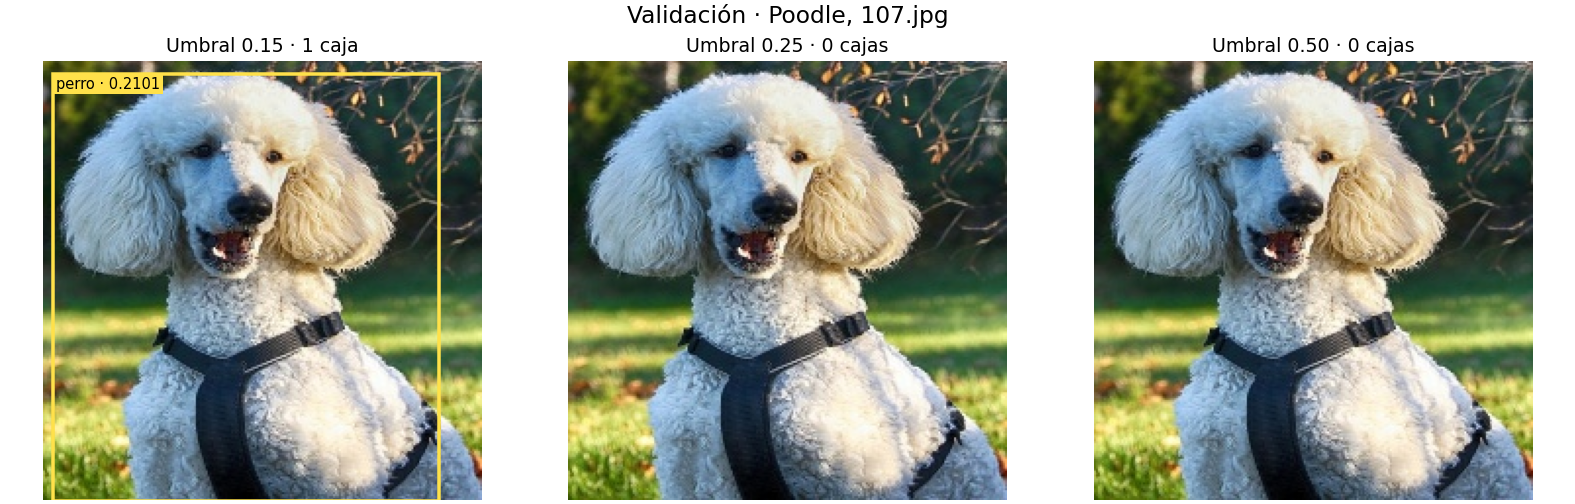

**La validación favorece `0.15`.**

In [5]:
def yolo_mostrar_cajas(evaluacion, ruta, titulo, altura):
    original = cv2.cvtColor(yolo_leer_imagen(ruta), cv2.COLOR_BGR2RGB)
    figura = Figure(figsize=(15, altura), layout="constrained")
    figura.suptitle(titulo, fontsize=16)
    resultados = evaluacion[evaluacion["Ruta"] == ruta].to_dict("records")
    for eje, resultado in zip(figura.subplots(1, 3), resultados, strict=True):
        cajas = resultado["Cajas"]
        eje.imshow(original)
        cantidad = "1 caja" if len(cajas) == 1 else f"{len(cajas)} cajas"
        eje.set_title(f"Umbral {resultado['Umbral']:.2f} · {cantidad}", fontsize=13)
        eje.set_axis_off()
        aciertos = iter(("#ffe14a", "#f259d8"))
        for (x1, y1, x2, y2), confianza, destino, revision in cajas:
            color = {
                "Falsa": "#4de0ff",
                "Duplicada": "#ffa85d",
            }.get(revision)
            if revision == "Acierto":
                color = next(aciertos, "#ffe14a")
            eje.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=color, lw=2.4))
            eje.annotate(
                f"{destino} · {confianza:.4f}", (x1, y1), xytext=(2, -2),
                textcoords="offset points", va="top", fontsize=10, color="black",
                bbox={"facecolor": color, "edgecolor": "none", "pad": 2},
            )
    with BytesIO() as salida:
        figura.savefig(salida, format="png", dpi=105)
        display(Image(data=salida.getvalue(), format="png", alt=titulo))

yolo_totales_validacion = yolo_validacion.groupby("Umbral")[YOLO_CONTEOS].sum()
display(yolo_totales_validacion.style.format_index("{:.2f}", axis=0))
yolo_elegido = min(
    YOLO_UMBRALES,
    key=lambda umbral: (
        yolo_totales_validacion.loc[umbral, "Omisiones"],
        yolo_totales_validacion.loc[umbral, "Cajas falsas"] + yolo_totales_validacion.loc[umbral, "Duplicadas"],
        abs(umbral - 0.25),
    ),
)
yolo_mostrar_cajas(yolo_validacion, "train/Poodle/107.jpg", "Validación anterior · Poodle, 107.jpg", 4.8)
display(Markdown(f"**La validación histórica favorece `{yolo_elegido:.2f}`.**"))

**Elección en la validación histórica.** `0.15` omitió 7 de los 22 perros, frente a 9 con `0.25` y 14 con `0.50`. Las cajas falsas y duplicadas fueron cero en los tres casos. Bajar de `0.25` a `0.15` recuperó el Poodle de la figura (0.2101) y el Bluetick (0.2040), cuya caja localiza la cabeza y el pecho. Todos los positivos son fotos individuales. Esta muestra aporta evidencia limitada sobre oclusiones y falsos positivos.

### Comprobación independiente

Se agrupan las filas por `path` para procesar cada foto una sola vez. La evaluación visual usa solo imágenes con anotaciones en `YOLO_REVISION`; las rutas nuevas se informan como pendientes hasta que se revisen las detecciones. Los resultados no representan todavía todo el manifiesto.

In [6]:
yolo_tipos = {
    "un_perro": "Fotos individuales",
    "varios_perros": "Escena con dos perros",
    "gato": "Gato",
    "perro_contexto": "Perro en contexto",
    "objeto_sin_animal": "Objeto sin animal",
}
yolo_rutas_independientes = {}
for yolo_fila in yolo_leer_manifiesto("independent_manifest.csv"):
    yolo_ruta = yolo_fila["path"]
    yolo_tipo = yolo_tipos[yolo_fila["scene_type"]]
    if yolo_rutas_independientes.setdefault(yolo_ruta, yolo_tipo) != yolo_tipo:
        raise ValueError(f"Tipos de escena distintos para {yolo_ruta}.")

yolo_pendientes = sorted(set(yolo_rutas_independientes) - set(YOLO_REVISION))
print(f"Fotos independientes pendientes de revisión visual: {len(yolo_pendientes)}")
for yolo_ruta in yolo_pendientes:
    print(f"  {yolo_ruta}")
yolo_revisadas = {ruta: tipo for ruta, tipo in sorted(yolo_rutas_independientes.items()) if ruta in YOLO_REVISION}
yolo_independiente = yolo_evaluar(yolo_revisadas)
yolo_totales_independiente = (
    yolo_independiente.groupby(["Tipo de caso", "Umbral"], sort=False)[YOLO_CONTEOS].sum()
)
display(yolo_totales_independiente.style.format_index("{:.2f}", level="Umbral", axis=0))
yolo_mostrar_revision(yolo_independiente)

Ruta,Perros visibles,0.15,0.25,0.50
independent/Beagle/beagle_001.jpg,perro,Acierto: perro (0.9361),Acierto: perro (0.9361),Acierto: perro (0.9361)
independent/Beagle/beagle_002.jpg,perro,Acierto: perro (0.9345),Acierto: perro (0.9345),Acierto: perro (0.9345)
independent/Bearded Collie/bearded_collie_001.jpg,perro,Acierto: perro (0.8126),Acierto: perro (0.8126),Acierto: perro (0.8126)
independent/Bearded Collie/bearded_collie_002.jpg,perro,Acierto: perro (0.5208),Acierto: perro (0.5208),Acierto: perro (0.5208)
independent/Border Collie/border_collie_001.jpg,perro,Acierto: perro (0.6253),Acierto: perro (0.6253),Acierto: perro (0.6253)
independent/Border Collie/border_collie_002.jpg,perro,Acierto: perro (0.9330),Acierto: perro (0.9330),Acierto: perro (0.9330)
independent/Chihuahua/chihuahua_001.jpg,perro,Acierto: perro (0.8686),Acierto: perro (0.8686),Acierto: perro (0.8686)
independent/Chihuahua/chihuahua_002.jpg,perro,Acierto: perro (0.6921),Acierto: perro (0.6921),Acierto: perro (0.6921)
independent/Chihuahua/chihuahua_003.jpg,perro,Acierto: perro (0.9193),Acierto: perro (0.9193),Acierto: perro (0.9193)
independent/Cockapoo/cockapoo_001.jpg,perro,Acierto: perro (0.6930),Acierto: perro (0.6930),Acierto: perro (0.6930)


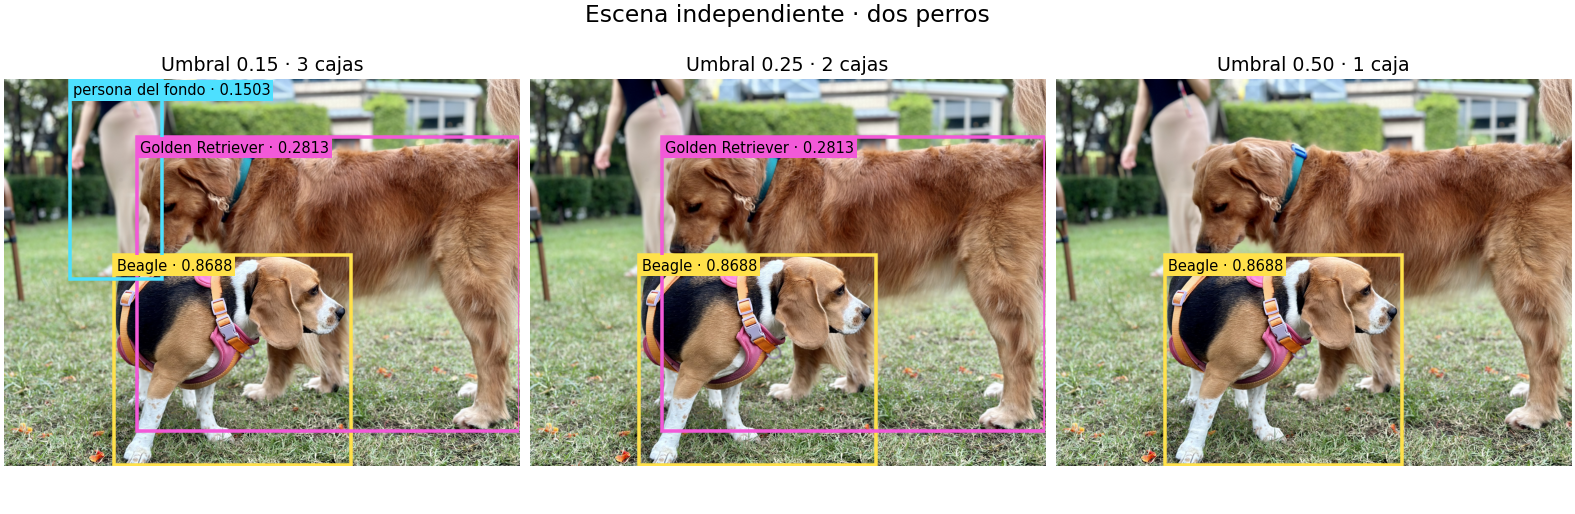

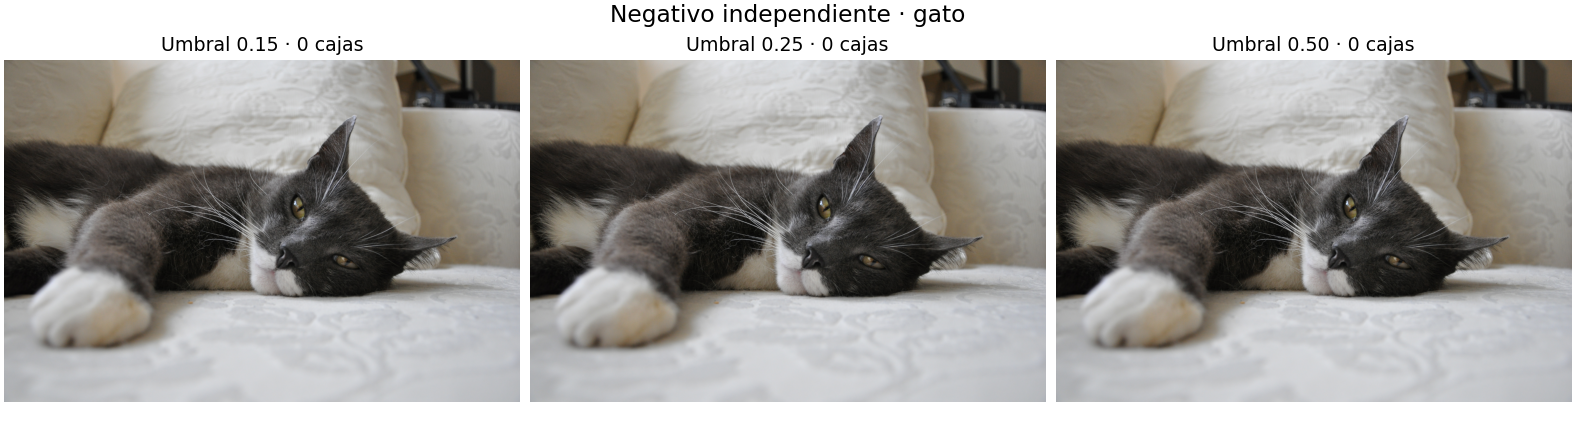

In [7]:
yolo_mostrar_cajas(
    yolo_independiente, "independent/escenas/escena_001.jpg", "Escena independiente · dos perros", 4.9
)
yolo_mostrar_cajas(
    yolo_independiente, "independent/sin_perro/gato_001.jpg", "Negativo independiente · gato", 4.1
)

El Beagle con arnés, en primer plano, tapa parte del Golden Retriever, que se inclina hacia él. Al fondo a la izquierda se ve una persona desenfocada con pantalón claro y cortada por el borde superior. Las cajas superpuestas del Beagle (0.8688) y del Golden Retriever (0.2813) localizan perros distintos. Con `0.50` queda solo la del Beagle. Al bajar de `0.25` a `0.15` aparece una caja falsa sobre la persona (0.1503) y se mantienen los mismos 26 perros detectados en el conjunto independiente. La foto del gato devuelve cero cajas con los tres umbrales.

Se conserva la elección de la validación histórica, `0.15`. Una sola escena con solapamiento permite describir este error, y la frecuencia de errores en otras escenas con personas u oclusión queda por medir.